# EntroPy：从因子研究到可交易组合

> 面向有数理基础、刚开始学习量化研究与量化交易的博士生

目标不是“跑出一条漂亮净值”，而是理解从 **信息时点 → 因子 → 统计证据 → 组合 → 成本 → 风险 → 生产监控** 的完整因果链。

本 notebook 直接调用 EntroPy 的真实模块，并用一套“我们知道数据生成真相”的小型合成市场做实验。这样既不依赖网络和 API key，也能区分“代码跑通”与“研究结论可信”。

学习完成后，你应能：

1. 解释项目各目录在研究流水线中的职责；
2. 从公式和源码两侧理解核心因子；
3. 正确处理 lag、direction、PIT、forward return 和横截面变换；
4. 用 IC、RankIC、分位数组合、换手、成本和稳定性评价因子；
5. 理解多重检验、冗余剔除、walk-forward 与 purging/embargo；
6. 从 alpha 构建有约束的组合，并完成成本感知回测；
7. 读懂 gross/net NAV、VaR/CVaR、benchmark attribution 和 capacity；
8. 知道研究原型距离真实交易还缺哪些契约和监控。

## 0. 使用方法与实验纪律

建议按顺序运行全部单元。默认 `RUN_SLOW=False`：主路径可在普通电脑上运行；设为 `True` 后，会额外计算较慢的状态空间/谱特征、完整 tearsheet 和 walk-forward。

请始终区分三件事：

- **定义**：因子公式想表达什么；
- **估计**：有限样本中如何测量它；
- **决策**：何时、以何约束把估计变成仓位。

合成数据的收益好坏没有投资意义。它只用于验证时间对齐、接口、统计量与会计恒等式。

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

_here = Path.cwd().resolve()
ROOT = next(p for p in (_here, _here.parent) if (p / "quant_platform").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from loguru import logger
logger.remove()

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.style.use("seaborn-v0_8-whitegrid")

SEED = 7
RUN_SLOW = False
print("project root:", ROOT)
print("slow sections:", RUN_SLOW)

project root: E:\Jupyter notebook\EntroPy
slow sections: False


## 1. 先看全局：项目是一条什么流水线？

$$
\text{raw data}
\rightarrow \text{PIT data}
\rightarrow \text{factor}
\rightarrow \text{effective signal}
\rightarrow \text{evidence}
\rightarrow \text{alpha}
\rightarrow \text{weights}
\rightarrow \text{trades}
\rightarrow \text{net PnL}
\rightarrow \text{decision}.
$$

| 层 | 项目位置 | 回答的问题 |
|---|---|---|
| 数据 | `core/data` | 当时可知道什么？谁可交易？ |
| 信号 | `core/signals` | 如何把信息压缩为预测变量？ |
| Alpha | `core/alpha_models` | 如何组合多个预测变量？ |
| 组合 | `core/portfolio` | 如何在风险与约束下分配权重？ |
| 执行 | `core/execution` | 权重变化如何变成交易和成本？ |
| 评价 | `core/evaluation` | 结果是否稳健、可归因、可扩容？ |
| 实验 | `core/experiments` | 如何固定配置并复现实验？ |
| 脚本 | `scripts` | 如何从命令行运行生产式流程？ |

最重要的边界是：**信号不是仓位，仓位不是成交，毛收益不是净收益。**

In [2]:
source_map = pd.DataFrame([
    ("PIT 与 schema", "quant_platform/core/data/schema.py"),
    ("因子抽象", "quant_platform/core/signals/base.py"),
    ("42 因子注册表", "quant_platform/core/signals/registry.py"),
    ("横截面变换", "quant_platform/core/signals/transforms.py"),
    ("effective signal", "quant_platform/core/signals/effective.py"),
    ("单因子评价", "quant_platform/core/signals/cross_sectional/evaluation.py"),
    ("多因子合成", "quant_platform/core/alpha_models/multi_factor.py"),
    ("组合构建", "quant_platform/core/portfolio/construction.py"),
    ("成本模型", "quant_platform/core/execution/cost_models/us_equity.py"),
    ("PnL", "quant_platform/core/execution/backtest/pnl.py"),
    ("实验运行器", "quant_platform/core/experiments/runner.py"),
], columns=["问题", "源码"])
source_map["绝对路径"] = source_map["源码"].map(lambda x: str(ROOT / x))
source_map

,问题,源码,绝对路径
0,PIT 与 schema,quant_platform/core/data/schema.py,E:\Jupyter notebook\EntroPy\quant_platform\cor...
1,因子抽象,quant_platform/core/signals/base.py,E:\Jupyter notebook\EntroPy\quant_platform\cor...
2,42 因子注册表,quant_platform/core/signals/registry.py,E:\Jupyter notebook\EntroPy\quant_platform\cor...
3,横截面变换,quant_platform/core/signals/transforms.py,E:\Jupyter notebook\EntroPy\quant_platform\cor...
4,effective signal,quant_platform/core/signals/effective.py,E:\Jupyter notebook\EntroPy\quant_platform\cor...
5,单因子评价,quant_platform/core/signals/cross_sectional/ev...,E:\Jupyter notebook\EntroPy\quant_platform\cor...
6,多因子合成,quant_platform/core/alpha_models/multi_factor.py,E:\Jupyter notebook\EntroPy\quant_platform\cor...
7,组合构建,quant_platform/core/portfolio/construction.py,E:\Jupyter notebook\EntroPy\quant_platform\cor...
8,成本模型,quant_platform/core/execution/cost_models/us_e...,E:\Jupyter notebook\EntroPy\quant_platform\cor...
9,PnL,quant_platform/core/execution/backtest/pnl.py,E:\Jupyter notebook\EntroPy\quant_platform\cor...


## 2. 量化研究的最小数学对象

对股票 \(i\)、交易日 \(t\)：

- 简单收益：\(\displaystyle r_{i,t}=P_{i,t}/P_{i,t-1}-1\)
- \(h\) 日前瞻收益：\(\displaystyle r^{(h)}_{i,t\to t+h}=P_{i,t+h}/P_{i,t}-1\)
- 信号：\(s_{i,t}\)，只能使用 \(t\) 时点可得信息
- 组合权重：\(w_{i,t}\)
- 次日毛收益：\(\displaystyle r^g_{p,t+1}=\sum_iw_{i,t}r_{i,t+1}\)
- 净值：\(\displaystyle NAV_{t+1}=NAV_t(1+r^g_{p,t+1})-C_{t+1}\)

一个因子研究其实在检验：

$$
\mathbb E[r_{i,t+1}\mid s_{i,t}] \text{ 是否随 }s_{i,t}\text{ 系统变化？}
$$

横截面研究在同一天比较股票；时间序列研究在同一资产上比较不同时点。二者的标准误、标签和交易解释不同，不能混用。

In [3]:
toy = pd.DataFrame({
    "ticker": ["A", "B", "C"],
    "weight_t": [0.50, 0.30, 0.20],
    "ret_t1": [0.02, -0.01, 0.005],
})
toy["contribution"] = toy["weight_t"] * toy["ret_t1"]
gross_ret = toy["contribution"].sum()
nav0, cost = 1_000_000.0, 350.0
nav1 = nav0 * (1 + gross_ret) - cost
display(toy)
print(f"gross return = {gross_ret:.4%}")
print(f"net NAV      = {nav1:,.2f}")
assert np.isclose(toy["weight_t"].sum(), 1.0)

,ticker,weight_t,ret_t1,contribution
0,A,0.5,0.020,0.010
1,B,0.3,-0.010,-0.003
2,C,0.2,0.005,0.001


gross return = 0.8000%
net NAV      = 1,007,650.00


## 3. 数据层：PIT 比“数据干净”更重要

项目的三张规范表都以 `(date, ticker)` 为键：

- `prices`：原始 OHLCV、`adj_factor`、`adj_close`、可交易标记；
- `universe`：上市天数、价格、市值、流动性与最终过滤结果；
- `fundamentals`：报告期、发布日期与“首次可用交易日”。

当前实现的保守时点口径：

$$
date_{\text{known}}
=\operatorname{nextTradingDay}(publish\_date+publication\_lag\_days).
$$

它防止把后来修订、晚于财报期末才发布的信息回填到过去。还要防范生存者偏差、事后复权泄漏、停牌/涨跌停不可成交、以及收盘后信息用于当日成交。

In [4]:
from quant_platform.core.data.schema import SCHEMA_MAP
from quant_platform.core.data.fundamentals import _apply_pit_lag

schema_rows = [{
    "table": table,
    "key": "(date, ticker)",
    "columns": ", ".join(schema.names),
} for table, schema in SCHEMA_MAP.items()]
display(pd.DataFrame(schema_rows))

filings = pd.DataFrame({
    "ticker": ["AAA", "BBB"],
    "report_date": pd.to_datetime(["2023-03-31", "2023-03-31"]),
    "publish_date": pd.to_datetime(["2023-04-25", "2023-05-08"]),
    "net_income": [10.0, 12.0],
})
pit = _apply_pit_lag(filings, "publish_date", lag_days=45)
pit[["ticker", "report_date", "publish_date", "date", "net_income"]]

,table,key,columns
0,prices,"(date, ticker)","date, ticker, open, high, low, close, volume, ..."
1,universe,"(date, ticker)","date, ticker, days_since_ipo, market_cap, clos..."
2,fundamentals,"(date, ticker)","date, ticker, report_date, publish_date, reven..."


,ticker,report_date,publish_date,date,net_income
0,AAA,2023-03-31,2023-04-25,2023-06-12,10.0
1,BBB,2023-03-31,2023-05-08,2023-06-23,12.0


## 4. 建造一个“知道真相”的小市场

真实市场没有可观测的“真 alpha”，所以调试研究系统时先用合成数据。本实验嵌入共同市场冲击、很弱的收益持续性、股票间不同的潜在质量、波动率和成交量。

生成式只是实验夹具，不是市场模型。若代码无法在已知真相的环境中识别结构，就更不应相信真实数据上的漂亮结果。

In [5]:
def make_synthetic_market(n_stocks=24, n_days=280, seed=SEED):
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range("2023-01-02", periods=n_days)
    tickers = [f"S{i:03d}" for i in range(n_stocks)]
    quality = np.linspace(-1.0, 1.0, n_stocks)
    rng.shuffle(quality)
    sigma = 0.009 + 0.009 * (1 - (quality + 1) / 2)
    shares = np.exp(16 + 0.30 * quality)
    prev_ret = np.zeros(n_stocks)
    close = np.full(n_stocks, 50.0)
    rows = []

    for dt in dates:
        market = 0.0001 + 0.005 * rng.normal()
        ret = (
            market + 0.12 * prev_ret + 0.00018 * quality
            - 0.00010 * (sigma - sigma.mean()) / sigma.std()
            + sigma * rng.normal(size=n_stocks)
        )
        ret = np.clip(ret, -0.12, 0.12)
        open_ = close * np.exp(0.25 * ret + rng.normal(0, 0.002, n_stocks))
        new_close = close * (1 + ret)
        width = np.abs(rng.normal(0.012, 0.003, n_stocks))
        high = np.maximum(open_, new_close) * (1 + width / 2)
        low = np.minimum(open_, new_close) * (1 - width / 2)
        volume = (1_500_000 * np.exp(0.5 * quality + rng.normal(0, 0.25, n_stocks))).astype(int)

        for j, ticker in enumerate(tickers):
            rows.append((
                dt, ticker, open_[j], high[j], low[j], new_close[j],
                volume[j], new_close[j] * volume[j], 1.0, new_close[j],
                True, shares[j] * new_close[j],
            ))
        close, prev_ret = new_close, ret

    columns = [
        "date", "ticker", "open", "high", "low", "close", "volume",
        "amount", "adj_factor", "adj_close", "is_tradable", "market_cap",
    ]
    prices = pd.DataFrame(rows, columns=columns).sort_values(["date", "ticker"])
    truth = pd.DataFrame({"ticker": tickers, "latent_quality": quality, "latent_sigma": sigma})
    return prices.reset_index(drop=True), truth

prices, latent_truth = make_synthetic_market()
print(prices.shape, prices["date"].min().date(), prices["date"].max().date())
display(prices.head())

(6720, 12) 2023-01-02 2024-01-26


,date,ticker,open,high,low,close,volume,amount,adj_factor,adj_close,is_tradable,market_cap
0,2023-01-02,S000,49.696745,50.080296,48.376563,48.752829,2064182,1.006347e+08,1.0,48.752829,True,4.746402e+08
1,2023-01-02,S001,49.638441,49.837725,47.812256,48.004982,994426,4.773740e+07,1.0,48.004982,True,3.507740e+08
2,2023-01-02,S002,49.698868,49.937822,49.173119,49.410687,2588569,1.279030e+08,1.0,49.410687,True,5.202042e+08
3,2023-01-02,S003,49.699494,50.045917,48.112876,48.450594,1035153,5.015378e+07,1.0,48.450594,True,3.449139e+08
4,2023-01-02,S004,49.937797,50.088178,49.553617,49.703292,1934804,9.616613e+07,1.0,49.703292,True,4.714335e+08


d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21069 (\N{CJK UNIFIED IDEOGRAPH-524D}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21482 (\N{CJK UNIFIED IDEOGRAPH-53EA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21512 (\N{CJK UNIFIED IDEOGRAPH-5408}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 32929 (\N{CJK UNIFIED IDEOGRAPH-80A1}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_

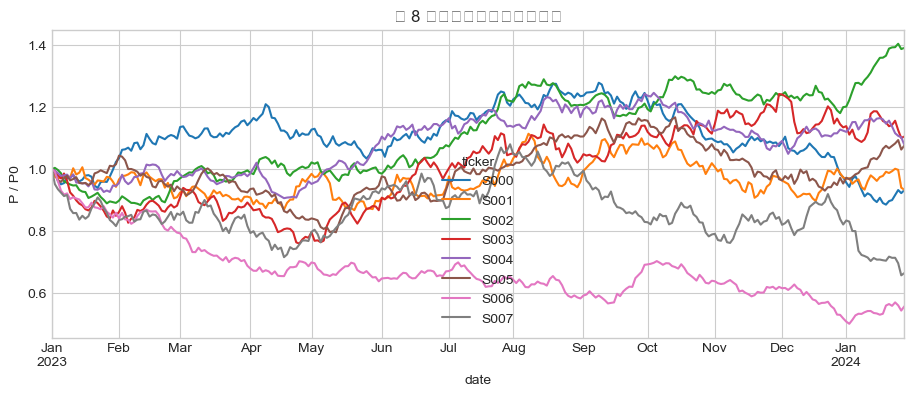

,ticker,latent_quality,latent_sigma
7,S007,-1.000000,0.018000
12,S012,-0.913043,0.017609
20,S020,-0.826087,0.017217
3,S003,-0.739130,0.016826


,ticker,latent_quality,latent_sigma
19,S019,0.739130,0.010174
21,S021,0.826087,0.009783
13,S013,0.913043,0.009391
18,S018,1.000000,0.009000


In [6]:
price_wide = prices.pivot(index="date", columns="ticker", values="adj_close")
(price_wide / price_wide.iloc[0]).iloc[:, :8].plot(
    figsize=(11, 4), title="前 8 只合成股票的归一化价格"
)
plt.ylabel("P / P0")
plt.show()
display(latent_truth.sort_values("latent_quality").head(4))
display(latent_truth.sort_values("latent_quality").tail(4))

## 5. 因子抽象：一个公式如何进入系统

所有因子继承 `FactorBase`，并提供 `FactorMeta`：唯一名称、类别、信号类型、lookback、lag、direction 和文献。

`FactorBase.compute()` 的实际流水线：

$$
raw\rightarrow lag\rightarrow missing\rightarrow winsorize\rightarrow zscore\rightarrow neutralize.
$$

方向统一在 `build_effective_signal()` 完成：

$$
s^{eff}_{i,t}
=\operatorname{rank}\left[
z\left(
\operatorname{neutralize}
(\operatorname{winsorize}(d\,s^{raw}_{i,t}))
\right)\right],
\quad d\in\{-1,+1\}.
$$

评价、选股和多因子组合应消费 effective signal，避免“低波动”在一个模块里做空、另一个模块里做多。

In [7]:
from quant_platform.core.signals.registry import FactorRegistry

registry = FactorRegistry()
registry.discover()
catalog = registry.list_factors()
print(f"registered factors: {len(catalog)}")
display(catalog.groupby(["signal_type", "category"]).size().rename("count").to_frame())
display(catalog[["name", "category", "signal_type", "lookback", "lag", "direction"]])

registered factors: 42


count
signal_type     category              
cross_sectional liquidity            8
                microstructure       1
                momentum             8
                quality              4
                value                2
                volatility           9
regime          regime               1
relative_value  mean_reversion       1
time_series     higher_moments       3
                noise_structure      2
                state_space          3

,name,category,signal_type,lookback,lag,direction
0,ABNORMAL_VOLUME,liquidity,cross_sectional,61,1,-1
1,ACCRUALS,quality,cross_sectional,1,1,-1
2,ACF_DECAY_60D,higher_moments,time_series,61,1,1
3,ASSET_GROWTH,quality,cross_sectional,252,1,-1
4,BOOK_TO_MARKET,value,cross_sectional,1,1,1
5,DOWNVOL_60D,volatility,cross_sectional,61,1,-1
6,EARNINGS_YIELD,value,cross_sectional,1,1,1
7,GROSS_PROFITABILITY,quality,cross_sectional,1,1,1
8,HMM_TURBULENCE_PROB,regime,regime,120,1,-1
9,HURST_60D,noise_structure,time_series,61,1,1


## 6. 变换细节

Lag 按 ticker 使用 `shift(lag)`。横截面截尾为：

$$
\tilde s_{i,t}=\min\{\max(s_{i,t},q_l),q_u\}.
$$

标准化和排序：

$$
z_{i,t}=\frac{s_{i,t}-\bar s_t}{\sigma_t},\qquad
rank_{i,t}=\frac{\operatorname{rank}(s_{i,t})-1}{N_t-1}.
$$

若暴露矩阵 \(X_t\) 包含截距、行业和 \(\log(MCap)\)，中性化使用回归残差：

$$
s_t=X_t\beta_t+\varepsilon_t,\qquad s^{neutral}_t=\varepsilon_t.
$$

中性化回答“控制已知暴露后还有没有增量信息”，但也可能删掉因子的经济来源，所以应比较前后结果。

In [8]:
from quant_platform.core.signals.effective import build_effective_signal

vol_cls = registry.get("VOL_20D")
vol_instance = vol_cls()
raw_series = vol_instance._compute(prices).reindex(prices.index)
raw_frame = prices[["date", "ticker", "market_cap"]].copy()
raw_frame["VOL_raw"] = raw_series.values

base_frame = vol_instance.compute(prices)
demo = base_frame.merge(prices[["date", "ticker", "market_cap"]], on=["date", "ticker"])
demo["log_mcap"] = np.log(demo["market_cap"])
effective_demo = build_effective_signal(
    demo, "VOL_20D", output_col="VOL_effective",
    direction=vol_cls.meta.direction,
    rank=True,
)
last_date = effective_demo["date"].max()
display(effective_demo.loc[effective_demo["date"] == last_date]
        .sort_values("VOL_effective", ascending=False).head(8))

,date,ticker,VOL_20D,market_cap,log_mcap,VOL_effective
262,2024-01-26,S000,-2.916612,4.423859e+08,19.907693,1.000000
6335,2024-01-26,S023,-2.197004,4.542425e+08,19.934142,0.958333
525,2024-01-26,S001,-1.086691,3.275915e+08,19.607278,0.916667
788,2024-01-26,S002,-0.809217,7.236006e+08,20.399750,0.875000
6064,2024-01-26,S022,-0.692982,2.132088e+08,19.177782,0.833333
5275,2024-01-26,S019,-0.265829,5.380877e+08,20.103532,0.791667
5012,2024-01-26,S018,-0.235935,6.093671e+08,20.227931,0.750000
5801,2024-01-26,S021,-0.220182,7.515320e+08,20.437624,0.708333


## 7. 核心因子 I：动量、反转与路径

项目的 1 月动量：

$$
MOM\_1M_{i,t}=\frac{P_{i,t}}{P_{i,t-21}}-1,\quad lag=1,\quad direction=+1.
$$

`STR_1M` 使用同一个 21 日原始收益，但 `direction=-1`：原始数据相同，经济假设相反。

`MOM_12_1M` 的精确实现是“252 日收益再由基类 lag 21 日”：

$$
s_{i,t}=\frac{P_{i,t-21}}{P_{i,t-273}}-1.
$$

这与某些文献写成 \(P_{t-21}/P_{t-252}-1\) 不完全相同。研究中要以源码和索引为准，不能只看标签。

路径动量：

$$
MOM\_PATH_{i,t}=
\frac{R^{(126)}_{i,t}}
{|\operatorname{MaxDrawdown}_{i,t-125:t}|}.
$$

残差动量先回归市场和 SMB 代理，再累计跳过最近一个月的残差：

$$
r_{i,t}=\alpha_i+\beta_{m,i}r_{m,t}+\beta_{s,i}SMB_t+\varepsilon_{i,t}.
$$

## 8. 核心因子 II：波动、尾部与流动性

20 日已实现波动率：

$$
VOL\_{20D,i,t}=\sqrt{252}\operatorname{Std}(r_{i,t-19:t}),\qquad direction=-1.
$$

`IDIOVOL` 取 60 日滚动 CAPM 残差标准差；`TAIL_RISK` 使用最差 5% 收益的条件均值；`REALIZED_JUMP` 使用双幂变差：

$$
RV=\sum r_t^2,\quad
BPV=\frac{\pi}{2}\sum |r_t||r_{t-1}|,\quad
JumpRatio=\max(0,1-BPV/RV).
$$

Amihud 非流动性：

$$
ILLIQ_{i,t}=10^6\operatorname{Mean}_{60}
\left(\frac{|r_{i,t}|}{Close_{i,t}Volume_{i,t}}\right),
\quad direction=-1.
$$

`SPREAD_HL` 从单日与两日高低价区间构造 Corwin–Schultz 隐含价差，再取 20 日均值。`PRICE_IMPACT` 近似：

$$
\lambda_i=\frac{\operatorname{Cov}(signedVolume,|r|)}
{\operatorname{Var}(signedVolume)}.
$$

流动性指标既可能含预期收益，也直接决定策略能否低成本成交。

## 9. 核心因子 III：价值、质量与财务时点

$$
EarningsYield=\frac{NetIncome_{TTM}}{MarketCap},\qquad
BookToMarket=\frac{BookEquity}{MarketCap},
$$

$$
GrossProfitability=\frac{GrossProfit_{TTM}}{TotalAssets},
$$

$$
AssetGrowth=\frac{Assets_t-Assets_{t-1y}}{Assets_{t-1y}},
\quad direction=-1,
$$

$$
Accruals=\frac{NetIncome_{TTM}-CFO_{TTM}}{TotalAssets},
\quad direction=-1.
$$

`PIOTROSKI_F8` 将盈利、现金流、杠杆、发行、毛利率和资产周转的 8 个二元指标求和；因 schema 缺少流动资产/负债，项目明确省略原始 F-score 的流动比率一项。

财务因子难点通常不是除法，而是 TTM 组成、同财季同比、市场值与财务快照的时点一致、修订数据和异常分母。

In [9]:
CORE_FACTORS = ["MOM_1M", "STR_1M", "VOL_20D", "ILLIQ_AMIHUD", "SPREAD_HL"]

factor_frame = registry.compute_all(
    prices,
    factor_names=CORE_FACTORS,
    use_cache=True,
)
coverage = factor_frame[CORE_FACTORS].notna().mean().rename("coverage")
meta = catalog.set_index("name").loc[
    CORE_FACTORS, ["category", "lookback", "lag", "direction"]
]
display(meta.join(coverage))
display(factor_frame.tail())

,category,lookback,lag,direction,coverage
name,,,,,
MOM_1M,momentum,22,1,1,0.921429
STR_1M,momentum,22,1,-1,0.921429
VOL_20D,volatility,21,1,-1,0.942857
ILLIQ_AMIHUD,liquidity,61,1,-1,0.853571
SPREAD_HL,liquidity,22,1,-1,0.942857


,date,ticker,MOM_1M,STR_1M,VOL_20D,ILLIQ_AMIHUD,SPREAD_HL
6715,2024-01-26,S019,0.178386,0.178386,-0.867169,-0.887908,0.0
6716,2024-01-26,S020,0.087746,0.087746,0.867693,1.711608,0.0
6717,2024-01-26,S021,0.393694,0.393694,-0.800244,-1.093545,0.0
6718,2024-01-26,S022,0.743023,0.743023,0.397275,1.505803,0.0
6719,2024-01-26,S023,1.066442,1.066442,-0.882189,-0.474746,0.0


## 10. 四类信号不能用同一把尺子

- `cross_sectional`：同日股票间排序，核心是 RankIC、分位数组合；
- `time_series`：每只资产自身状态，核心是方向准确率、条件命中率；
- `regime`：调节总风险暴露，核心是状态区分与危机覆盖；
- `relative_value`：价差均值回复，核心是 half-life、入场/出场与配对稳定性。

高级模块：

- Kalman：\(x_t=Fx_{t-1}+w_t,\ y_t=Hx_t+v_t\)，输出过滤价格、速度、噪声比；
- 谱熵：\(H=-\sum_kp_k\log p_k/\log K\)，越接近 1 越像宽频噪声；
- Hurst：\(E[R/S]\propto n^H\)，\(H>0.5\) 偏持续；
- HMM：输出高波动状态后验概率；
- OU：\(dX_t=\kappa(\mu-X_t)dt+\sigma dW_t\)，输出平稳标准差 z-score。

typed signal 应通过评价 router 选择对应 scorecard，而不是强行套用横截面 IC。

In [11]:
from quant_platform.core.signals.evaluation.router import get_scorecard

routing = (
    catalog[["signal_type"]].drop_duplicates()
    .assign(scorecard=lambda x: x["signal_type"].map(lambda t: get_scorecard(t).__name__))
)
display(routing)

if RUN_SLOW:
    typed = registry.compute_all(
        prices,
        factor_names=["KF_TREND_STRENGTH", "SPECTRAL_ENTROPY_60D", "HURST_60D"],
    )
    display(typed.tail())
else:
    print("跳过较慢的状态空间/谱特征计算；将 RUN_SLOW=True 后可运行。")

,signal_type,scorecard
0,cross_sectional,CrossSectionalScorecard
2,time_series,TimeSeriesScorecard
8,regime,RegimeScorecard
21,relative_value,RelativeValueScorecard


跳过较慢的状态空间/谱特征计算；将 RUN_SLOW=True 后可运行。


## 11. 标签：forward return 只能用于评价

项目构造：

$$
fwd\_ret_h(t)=\frac{P_{t+h}}{P_t}-1.
$$

它是标签 \(y_t\)，在 \(t\) 时未知。rolling normalization、特征选择或模型训练若使用测试期标签，就会泄漏。

当 \(h>1\) 时，相邻标签共享未来收益，例如 5 日标签相邻两期重叠 4 天。这令 IC 序列自相关，也是使用 Newey–West 标准误和 purging 的原因。

In [12]:
from quant_platform.core.signals.cross_sectional.evaluation import add_forward_returns

labeled_prices = add_forward_returns(prices, periods=[1, 5, 10])
research = labeled_prices.merge(
    factor_frame,
    on=["date", "ticker"],
    how="left",
    validate="one_to_one",
)

one = research.loc[research["ticker"] == research["ticker"].iloc[0]].sort_values("date")
row = one.iloc[100]
manual_5d = one.iloc[105]["adj_close"] / row["adj_close"] - 1
print("project label:", row["fwd_ret_5d"])
print("manual label :", manual_5d)
assert np.isclose(row["fwd_ret_5d"], manual_5d)

project label: -0.004007620357550201
manual label : -0.004007620357550201


## 12. 单因子评价：从相关性到经济可交易性

$$
IC_t=\operatorname{Corr}_i(s_{i,t},r_{i,t+1}),\qquad
RankIC_t=\operatorname{Spearman}_i(s_{i,t},r_{i,t+1}),
$$

$$
ICIR=\frac{\overline{IC}}{\sigma(IC)}\sqrt{252}.
$$

Newey–West HAC 标准误使用 Bartlett 权重：

$$
\widehat{\operatorname{Var}}_{HAC}(\bar x)=
\frac{1}{T}\left[\hat\gamma_0+
2\sum_{k=1}^{L}\left(1-\frac{k}{L+1}\right)\hat\gamma_k\right].
$$

统计显著不等于可交易，还要看分位收益单调性、long/short 腿、换手与盈亏平衡成本，以及规模、流动性、状态和子样本稳定性。

In [13]:
from quant_platform.core.signals.cross_sectional.evaluation import (
    compute_rank_ic_series,
    ic_summary,
    long_short_returns,
    factor_turnover,
)
from quant_platform.core.signals.effective import build_effective_signal

evaluation_rows = []
effective_frames = {}

for name in CORE_FACTORS:
    eff = build_effective_signal(
        research, name,
        direction=registry.get(name).meta.direction,
        rank=True,
    )
    effective_frames[name] = eff
    ric = compute_rank_ic_series(eff, name, return_col="fwd_ret_1d")
    stats = ic_summary(ric)
    ls = long_short_returns(eff, name, return_col="fwd_ret_1d")
    turnover = factor_turnover(eff, name)
    mean_to = turnover.mean()
    ls_sharpe = (
        ls.mean() / ls.std(ddof=1) * np.sqrt(252)
        if len(ls) > 2 and ls.std(ddof=1) > 0 else np.nan
    )
    break_even = (
        ls.mean() / mean_to * 10_000
        if pd.notna(mean_to) and mean_to > 0 else np.nan
    )
    evaluation_rows.append({
        "factor": name,
        "RankIC": stats["mean_ic"],
        "ICIR": stats["icir"],
        "NW_t": stats["nw_t_stat"],
        "NW_p": stats["nw_p_value"],
        "hit_rate": stats["hit_rate"],
        "LS_Sharpe_gross": ls_sharpe,
        "mean_signal_turnover": mean_to,
        "break_even_cost_bps": break_even,
    })

evaluation = pd.DataFrame(evaluation_rows).set_index("factor")
display(evaluation.round(4))

d:\ProgramData\Anaconda\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
d:\ProgramData\Anaconda\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,RankIC,ICIR,NW_t,NW_p,hit_rate,LS_Sharpe_gross,mean_signal_turnover,break_even_cost_bps
factor,,,,,,,,
MOM_1M,0.0103,0.7787,0.7407,0.4589,0.5175,0.5153,0.0588,49.9917
STR_1M,-0.0103,-0.7787,-0.7407,0.4589,0.4825,-0.5153,0.0588,-49.9917
VOL_20D,0.0300,2.3596,2.2350,0.0254,0.5894,1.6491,0.0371,248.9459
ILLIQ_AMIHUD,0.0345,2.6039,2.3579,0.0184,0.5546,2.2313,0.0026,4948.7535
SPREAD_HL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


d:\ProgramData\Anaconda\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 32047 (\N{CJK UNIFIED IDEOGRAPH-7D2F}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 35745 (\N{CJK UNIFIED IDEOGRAPH-8BA1}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21512 (\N{CJK UNIFIED IDEOGRAPH-5408}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


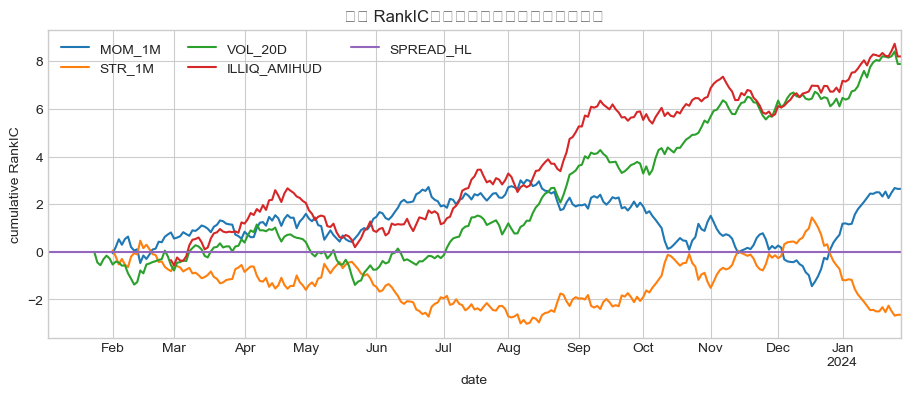

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
for name, eff in effective_frames.items():
    ric = compute_rank_ic_series(eff, name, return_col="fwd_ret_1d")
    ric.fillna(0).cumsum().plot(ax=ax, label=name)
ax.set_title("累计 RankIC（合成数据，仅用于接口验证）")
ax.set_ylabel("cumulative RankIC")
ax.legend(ncol=3)
plt.show()

## 13. 分位数组合、腿归因与换手

每日按 effective signal 分成 \(Q\) 组：

$$
LS_t=\bar r_{Q,t+1}-\bar r_{1,t+1}.
$$

项目的信号换手代理：

$$
Turnover^{signal}_t=1-\rho_S(rank(s_t),rank(s_{t-1})).
$$

真实组合单边换手则是：

$$
Turnover^{portfolio}_t=\frac12\sum_i|w_{i,t}-w_{i,t-1}|.
$$

二者分别属于研究层和执行层，不能混为一个指标。

d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20301 (\N{CJK UNIFIED IDEOGRAPH-4F4D}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 32452 (\N{CJK UNIFIED IDEOGRAPH-7EC4}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\ProgramData\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21512 (\N{CJK UNIFIED IDEOGRAPH-5408}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_

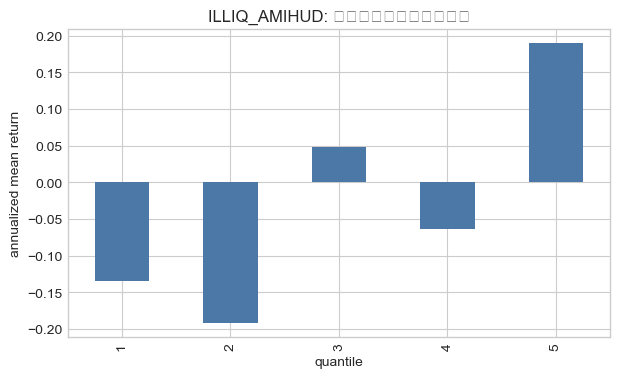

chosen factor: ILLIQ_AMIHUD


,leg attribution
long_leg_mean,0.000887
short_leg_mean,0.000399
long_leg_sharpe,3.1063
short_leg_sharpe,0.9821
long_share_of_ls,0.6897
short_share_of_ls,0.3103
long_only_compatible,True


In [15]:
from quant_platform.core.signals.cross_sectional.evaluation import (
    quantile_returns,
    long_short_leg_attribution,
)

chosen_factor = evaluation["RankIC"].idxmax()
chosen_eff = effective_frames[chosen_factor]
qr = quantile_returns(chosen_eff, chosen_factor, "fwd_ret_1d", n_quantiles=5)
q_ann = qr.groupby("quantile")["mean_ret"].mean() * 252
leg = long_short_leg_attribution(chosen_eff, chosen_factor, "fwd_ret_1d")

fig, ax = plt.subplots(figsize=(7, 4))
q_ann.plot.bar(ax=ax, color="#4C78A8")
ax.set_title(f"{chosen_factor}: 分位数组合年化平均收益")
ax.set_ylabel("annualized mean return")
plt.show()

print("chosen factor:", chosen_factor)
display(pd.Series(leg, name="leg attribution").to_frame())

### 完整 tearsheet（可选慢单元）

`factor_tearsheet()` 还计算多期限 IC、成本调整 Sharpe、横截面/状态/子样本稳定性和 alpha half-life：

$$
IC(h)=IC_0e^{-h/\tau},\qquad half\text{-}life=\tau\ln2.
$$

它适合候选因子的深入审查，不适合对数百个随手构造的变量反复调用。

In [16]:
from quant_platform.core.signals.cross_sectional.evaluation import factor_tearsheet

if RUN_SLOW:
    full_sheet = factor_tearsheet(
        research,
        chosen_factor,
        direction=registry.get(chosen_factor).meta.direction,
        forward_periods=[1, 5, 10],
        cost_bps_per_turnover=10.0,
    )
    display(pd.Series(full_sheet["rank_ic_stats"], name="RankIC"))
    display(pd.Series(full_sheet["advanced_metrics"], name="advanced"))
else:
    print("跳过完整 tearsheet；将 RUN_SLOW=True 后可运行。")

跳过完整 tearsheet；将 RUN_SLOW=True 后可运行。


## 14. 多重检验与回测过拟合

同时试验 \(m\) 个无效因子，每个按 5% 判断，至少一个假阳性的概率为：

$$
1-(1-0.05)^m.
$$

项目提供 BH-FDR、White Reality Check、Hansen SPA、Deflated Sharpe 和 CSCV/PBO。BH 对排序后的 p-value 寻找最大 \(k\)：

$$
p_{(k)}\le\frac{k}{m}q.
$$

必须把失败研究也计入试验次数；只保存赢家会让任何修正失效。

In [17]:
from quant_platform.core.signals.factor_selection import benjamini_hochberg, hansen_spa_test

evaluation["FDR_q"] = benjamini_hochberg(evaluation["NW_p"])
evaluation["FDR_pass_10pct"] = evaluation["FDR_q"] <= 0.10
display(evaluation[["RankIC", "NW_p", "FDR_q", "FDR_pass_10pct"]].round(4))

if RUN_SLOW:
    ls_dict = {
        name: long_short_returns(eff, name, "fwd_ret_1d")
        for name, eff in effective_frames.items()
    }
    spa = hansen_spa_test(ls_dict, n_boot=300, random_state=SEED)
    display(pd.Series(spa, name="Hansen SPA"))
else:
    print("SPA bootstrap 已跳过；正式研究应增加 bootstrap 次数。")

,RankIC,NW_p,FDR_q,FDR_pass_10pct
factor,,,,
MOM_1M,0.0103,0.4589,0.4589,False
STR_1M,-0.0103,0.4589,0.4589,False
VOL_20D,0.0300,0.0254,0.0508,True
ILLIQ_AMIHUD,0.0345,0.0184,0.0508,True
SPREAD_HL,NaN,NaN,NaN,False


SPA bootstrap 已跳过；正式研究应增加 bootstrap 次数。


## 15. 冗余不是只看原始相关系数

两个因子可能在三种意义上重复：

1. **信号相关**：同日股票排序相似；
2. **收益相关**：各自 long-short 收益相似；
3. **暴露相似**：对规模、行业、波动等风险变量的投影相似。

项目以 \(1-|\rho|\) 为距离做层次聚类，并在簇内保留证据最强的代表。组合因子的目标不是收集最多名字，而是收集互补信息。

`MOM_1M` 和 `STR_1M` 的原始计算相同、方向相反；统一为“越大越好”后应近乎完全负相关，不能当作两个独立证据。

,MOM_1M,STR_1M,VOL_20D,ILLIQ_AMIHUD,SPREAD_HL
MOM_1M,1.00,-1.00,0.12,0.15,0.01
STR_1M,-1.00,1.00,-0.12,-0.15,-0.01
VOL_20D,0.12,-0.12,1.00,0.76,-0.01
ILLIQ_AMIHUD,0.15,-0.15,0.76,1.00,-0.01
SPREAD_HL,0.01,-0.01,-0.01,-0.01,1.00


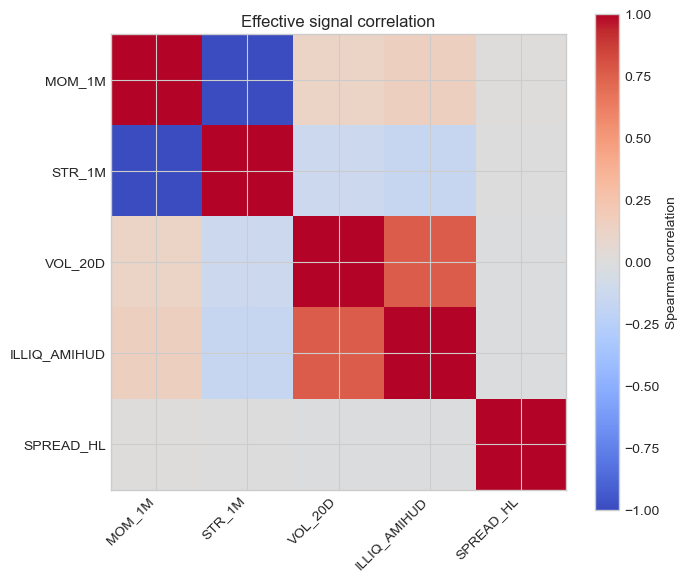

In [18]:
from quant_platform.core.signals.redundancy import factor_signal_correlation

direction_map = {name: registry.get(name).meta.direction for name in CORE_FACTORS}
signal_corr = factor_signal_correlation(
    research,
    CORE_FACTORS,
    direction_map=direction_map,
)
display(signal_corr.round(2))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(signal_corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(signal_corr)), signal_corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(signal_corr)), signal_corr.index)
fig.colorbar(im, ax=ax, label="Spearman correlation")
ax.set_title("Effective signal correlation")
plt.tight_layout()
plt.show()

## 16. 多因子合成：先统一方向，再只用历史估权重

$$
\alpha_{i,t}=\sum_{k=1}^K a_{k,t}s^{eff}_{i,k,t}.
$$

项目实现：

1. `rolling_icir`：\(\displaystyle a_{k,t}\propto
\overline{IC}_{k,t-L:t-1}/\sigma(IC_{k,t-L:t-1})\)
2. `mean_variance`：\(\displaystyle a_t\propto(\Sigma_{factor}+\lambda I)^{-1}\mu\)
3. `risk_parity`：\(\displaystyle a_{k,t}\propto1/\sigma_{k,t}\)
4. `orthogonal_incremental`：候选信号先对 baseline 回归，残差再估权重。

源码中的 rolling mean/std 和 factor volatility 都在估计后 `shift(1)`，这是防止当日标签泄漏的关键；缺少历史时回退等权。

In [19]:
from quant_platform.core.alpha_models.multi_factor import (
    MultiFactorCombiner,
    MultiFactorConfig,
    infer_factor_metadata,
)

COMBINE_FACTORS = ["MOM_1M", "VOL_20D", "ILLIQ_AMIHUD", "SPREAD_HL"]
combine_direction, combine_category = infer_factor_metadata(COMBINE_FACTORS)

combiner = MultiFactorCombiner(
    MultiFactorConfig(
        method="rolling_icir",
        lookback=63,
        min_periods=20,
        output_col="alpha_multi",
    ),
    direction_map=combine_direction,
    category_map=combine_category,
)
alpha_frame = combiner.fit_transform(
    research,
    COMBINE_FACTORS,
    return_col="fwd_ret_1d",
)
display(combiner.factor_weights_.tail(8).round(3))
display(alpha_frame[["date", "ticker", "alpha_multi"]].dropna().tail())

d:\ProgramData\Anaconda\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,MOM_1M,VOL_20D,ILLIQ_AMIHUD,SPREAD_HL,date
272,0.222,0.464,0.314,0.0,2024-01-17
273,0.236,0.463,0.301,0.0,2024-01-18
274,0.246,0.444,0.310,0.0,2024-01-19
275,0.250,0.465,0.285,0.0,2024-01-22
276,0.213,0.496,0.291,0.0,2024-01-23
277,0.178,0.495,0.328,0.0,2024-01-24
278,0.210,0.438,0.352,0.0,2024-01-25
279,0.281,0.407,0.313,0.0,2024-01-26


,date,ticker,alpha_multi
6715,2024-01-22,S023,0.683186
6716,2024-01-23,S023,0.677958
6717,2024-01-24,S023,0.661569
6718,2024-01-25,S023,0.681101
6719,2024-01-26,S023,0.749924


## 17. Regime overlay：改变风险预算，不要伪装成选股因子

HMM turbulence probability 更适合决定总风险，而不是直接做横截面排序。项目的 `RegimePolicy` 可在高风险状态下缩放 alpha、降低净暴露、提高再平衡阈值、禁用类别或改变类别权重。

$$
\alpha^{regime}_{i,t}=g(z_t)\alpha_{i,t},\qquad
E_t=
\begin{cases}
E_{high}, & p_t^{turb}>\theta,\\
E_{low}, & \text{otherwise}.
\end{cases}
$$

状态模型必须只用截至 \(t\) 的数据拟合；用全样本 HMM 再回填后验概率会泄漏。

In [20]:
from quant_platform.core.alpha_models.multi_factor import RegimePolicy

regime_policy = RegimePolicy(
    regime_col="HMM_TURBULENCE_PROB",
    threshold=0.60,
    reduction_factor=0.50,
    high_regime_net_exposure=0.50,
    low_regime_net_exposure=1.00,
    high_regime_rebalance_threshold=0.05,
    low_regime_rebalance_threshold=0.02,
    disabled_categories_high=("momentum",),
)
display(pd.Series(regime_policy.__dict__, name="policy").to_frame())

,policy
regime_col,HMM_TURBULENCE_PROB
threshold,0.6
reduction_factor,0.5
high_regime_net_exposure,0.5
low_regime_net_exposure,1.0
high_regime_rebalance_threshold,0.05
low_regime_rebalance_threshold,0.02
disabled_categories_high,"(momentum,)"
category_multipliers_high,{}
category_multipliers_low,{}


## 18. 从 alpha 到组合

分位数组合提供透明 baseline。逆波动权重：

$$
w_i=\frac{1/\sigma_i}{\sum_j1/\sigma_j},
$$

但没有处理资产相关性。

项目优化器求解：

$$
\min_w-\alpha^\top w+\frac{\lambda}{2}w^\top\Sigma w
+\eta\|w-w_{prev}\|_2^2,
$$

并施加 long-only 或 dollar-neutral、单股上限和可选换手约束。协方差向对角阵收缩：

$$
\hat\Sigma=(1-\delta)S+\delta\operatorname{diag}(S).
$$

优化器不是 alpha 生成器。若 \(\alpha\)、\(\Sigma\) 的尺度、稳定性和约束可行性不清楚，精确解只会精确放大估计误差。

In [21]:
from quant_platform.core.portfolio.quantile import QuantilePortfolio
from quant_platform.core.portfolio.construction import (
    PortfolioConfig,
    PortfolioMode,
    WeightScheme,
)

signal = alpha_frame[["date", "ticker", "alpha_multi"]].dropna()
universe = prices[["date", "ticker", "market_cap"]].copy()
universe["pass_all_filters"] = True

rebalance = (
    prices.groupby(prices["date"].dt.to_period("M"))["date"]
    .max().sort_values()
)
rebalance = pd.DatetimeIndex(rebalance.values, name="date")
rebalance = rebalance.intersection(pd.DatetimeIndex(signal["date"].unique(), name="date"))
rebalance.name = "date"

portfolio_cfg = PortfolioConfig(
    mode=PortfolioMode.LONG_SHORT,
    weight_scheme=WeightScheme.EQUAL,
    n_quantiles=5,
    rebalance_freq="M",
    max_stock_weight=1.0,
)
target_weights = QuantilePortfolio(portfolio_cfg).build(
    signal, universe, rebalance
)

weight_check = target_weights.groupby("date")["weight"].agg(
    net="sum",
    gross=lambda x: x.abs().sum(),
    holdings="size",
)
display(weight_check.tail())

,net,gross,holdings
date,,,
2023-09-29,1.0,1.0,10
2023-10-31,1.0,1.0,10
2023-11-30,1.0,1.0,10
2023-12-29,1.0,1.0,10
2024-01-26,1.0,1.0,10


## 19. 风险模型：系统因子与特质项

$$
r_t=Bf_t+\varepsilon_t,\qquad
\Sigma_{stock}=B\Sigma_fB^\top+D.
$$

组合方差：

$$
\sigma_p^2=w^\top B\Sigma_fB^\top w+w^\top Dw.
$$

项目用时间序列 OLS 估 beta，用指数加权协方差和对角收缩估 \(\Sigma_f\)，用残差估 specific risk。

风险模型必须检查因子收益与 specific risk 的频率/年化单位、暴露矩阵秩与缺失、协方差条件数与正定性，以及风险贡献能否加回总方差。

In [22]:
from quant_platform.core.portfolio.risk_model import FactorRiskModel

stock_returns = price_wide.pct_change().dropna()
mkt_ret = stock_returns.mean(axis=1)
mcap0 = prices.groupby("ticker")["market_cap"].first()
small = mcap0.nsmallest(6).index
big = mcap0.nlargest(6).index
smb_ret = stock_returns[small].mean(axis=1) - stock_returns[big].mean(axis=1)
factor_returns = pd.DataFrame({"market": mkt_ret, "SMB_proxy": smb_ret}).dropna()

risk_model = FactorRiskModel(halflife=60, shrinkage=0.5).fit(
    stock_returns.loc[factor_returns.index],
    factor_returns,
)
latest_w = (
    target_weights.loc[target_weights["date"] == target_weights["date"].max()]
    .set_index("ticker")["weight"]
)
risk_decomp = risk_model.decompose_risk(latest_w)
display(pd.Series({
    k: v for k, v in risk_decomp.items()
    if k not in {"factor_contributions", "portfolio_exposures"}
}, name="risk decomposition"))
display(pd.Series(risk_decomp["portfolio_exposures"], name="portfolio exposure"))

total_risk           0.067796
factor_risk          0.006033
specific_risk        0.067527
factor_variance      0.000036
specific_variance    0.004560
Name: risk decomposition, dtype: float64

market       1.026956
SMB_proxy    0.046650
Name: portfolio exposure, dtype: float64

## 20. 再平衡、交易与成本

真实单边换手：

$$
TO_t=\frac12\sum_i|w^{target}_{i,t}-w^{held}_{i,t^-}|.
$$

美国股票成本模型：

$$
Cost=Commission+Slippage+Impact+RegulatoryFees+Borrow,
$$

平方根冲击：

$$
Impact=c\,\sigma_{daily}
\left(\frac{Shares}{ADV}\right)^\gamma Notional,
\quad \gamma=0.5.
$$

冲击是非线性的，资本放大十倍不会保持相同 bps 成本。卖出含 SEC/FINRA 费用；空头每天产生 borrow cost。

In [23]:
from quant_platform.core.portfolio.rebalance import carry_forward_weights
from quant_platform.core.execution.cost_models.us_equity import CostModel, estimate_trade_cost
from quant_platform.core.execution.backtest.vectorized_daily import simulate_execution

all_dates = pd.DatetimeIndex(sorted(prices["date"].unique()), name="date")
daily_weights = carry_forward_weights(target_weights, all_dates)

cost_model = CostModel(
    commission_per_share=0.005,
    slippage_bps=3.0,
    impact_coeff=0.08,
    impact_exponent=0.5,
    borrow_rate_annual=0.005,
)

example_cost = estimate_trade_cost(
    side="buy", shares=20_000, price=50.0,
    adv_shares=1_000_000, daily_vol=0.02,
    model=cost_model,
)
display(pd.Series(example_cost, name="one trade"))

trades = simulate_execution(
    daily_weights, prices,
    cost_model=cost_model,
    initial_capital=1_000_000.0,
)
print("daily weight rows:", len(daily_weights))
print("executed trades:", len(trades))
display(trades.head())

notional          1000000.0000
commission            100.0000
slippage              300.0000
impact                226.2742
sec_fee                 0.0000
finra_taf               0.0000
stamp_duty              0.0000
total_cost            626.2742
total_cost_bps          6.2600
Name: one trade, dtype: float64

daily weight rows: 2590
executed trades: 112


,date,ticker,weight_from,weight_to,delta_weight,side,notional_trade,price,shares,adv_shares,daily_vol,notional,commission,slippage,impact,sec_fee,finra_taf,stamp_duty,total_cost,total_cost_bps,portfolio_value_before_trade
0,2023-01-31,S002,0.0,0.1,0.1,buy,100000.0,44.039694,2271.0,2257679.15,0.009160,100014.14,11.355,30.0042,2.3244,0.0,0.0,0.0,43.6837,4.37,1000000.0
1,2023-01-31,S007,0.0,0.1,0.1,buy,100000.0,38.579605,2592.0,1027131.20,0.019161,99998.34,12.960,29.9995,7.7004,0.0,0.0,0.0,50.6599,5.07,1000000.0
2,2023-01-31,S012,0.0,0.1,0.1,buy,100000.0,51.056381,1959.0,926917.95,0.020811,100019.45,9.795,30.0058,7.6555,0.0,0.0,0.0,47.4563,4.74,1000000.0
3,2023-01-31,S013,0.0,0.1,0.1,buy,100000.0,44.983597,2223.0,2344084.85,0.011117,99998.54,11.115,29.9996,2.7388,0.0,0.0,0.0,43.8534,4.39,1000000.0
4,2023-01-31,S014,0.0,0.1,0.1,buy,100000.0,44.325621,2256.0,1599791.40,0.019644,99998.60,11.280,29.9996,5.9014,0.0,0.0,0.0,47.1810,4.72,1000000.0


## 21. PnL：必须同时保留 gross 与 net

$$
r^g_{p,t}=\sum_iw_{i,t}r_{i,t},
$$

$$
NAV^g_t=NAV^g_{t-1}(1+r^g_{p,t}),
$$

$$
NAV^n_t=NAV^n_{t-1}(1+r^g_{p,t})-TC_t-BC_t.
$$

回撤：

$$
DD_t=\frac{NAV_t}{\max_{\tau\le t}NAV_\tau}-1.
$$

应核对：正成本下净 NAV 不应系统性高于毛 NAV；无交易日成本为零；移除持仓时产生平仓交易。

,performance
gross_ann_return,-0.007579
gross_ann_vol,0.100699
gross_sharpe,-0.0753
gross_sortino,-0.1161
gross_calmar,-0.0722
gross_max_drawdown,-0.104979
net_ann_return,-0.012634
net_ann_vol,0.100705
net_sharpe,-0.1255
net_sortino,-0.1943


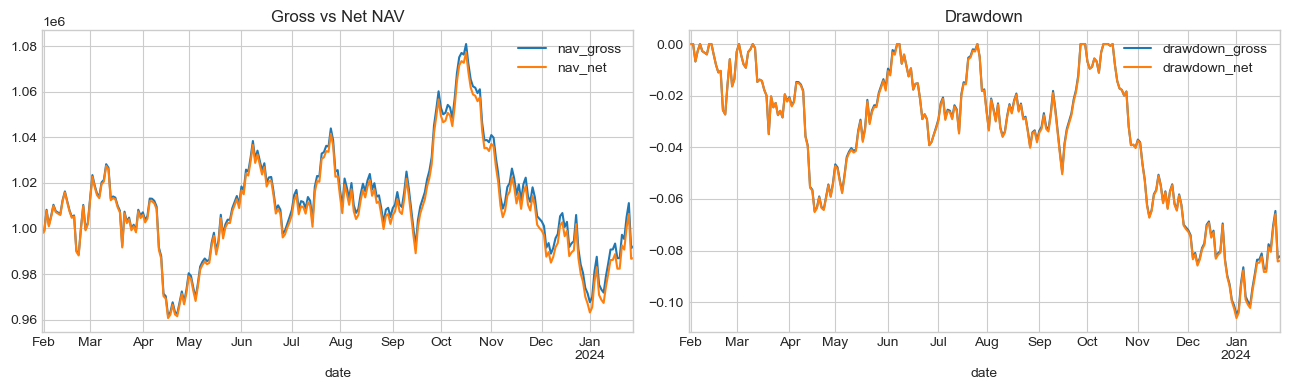

In [24]:
from quant_platform.core.execution.backtest.pnl import compute_daily_returns, performance_summary

pnl = compute_daily_returns(
    daily_weights,
    prices,
    trades=trades,
    cost_model=cost_model,
    initial_capital=1_000_000.0,
)
summary = performance_summary(pnl)
display(pd.Series(summary, name="performance").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pnl[["nav_gross", "nav_net"]].plot(ax=axes[0], title="Gross vs Net NAV")
pnl[["drawdown_gross", "drawdown_net"]].plot(ax=axes[1], title="Drawdown")
plt.tight_layout()
plt.show()

assert (pnl["trading_cost_dollar"] >= 0).all()

## 22. 风险、基准与容量

### VaR / CVaR

历史 VaR 来自收益分位点；CVaR 是超过 VaR 后的平均尾部损失：

$$
CVaR_\alpha=-E[r\mid r\le q_{1-\alpha}].
$$

正态参数 VaR 对偏度和肥尾不稳健；项目同时提供 Cornish–Fisher 修正和 VaR violations 回测。

### 基准归因

主动收益 \(a_t=r_{p,t}-r_{b,t}\)：

$$
TE=\sqrt{252}\sigma(a_t),\qquad
IR=\frac{252\bar a}{TE}.
$$

CAPM：

$$
r_p-r_f=\alpha+\beta(r_b-r_f)+\varepsilon.
$$

### 容量

资本增大使 participation rate 与平方根冲击上升，净 Sharpe 逐步下降。容量应是一条资本—成本—净收益曲线，而非单一成交额。

In [25]:
from quant_platform.core.evaluation.risk_metrics import risk_metrics_summary
from quant_platform.core.evaluation.benchmark_analytics import benchmark_analysis
from quant_platform.core.evaluation.capacity import capacity_analysis

risk_summary = risk_metrics_summary(pnl["net_ret"], confidence=0.95)

benchmark_returns = (
    prices.sort_values(["ticker", "date"])
    .assign(stock_ret=lambda x: x.groupby("ticker")["adj_close"].pct_change())
    .groupby("date")["stock_ret"].mean()
)
benchmark_summary = benchmark_analysis(
    pnl["net_ret"],
    benchmark_returns,
    risk_free_rate=0.0,
)

display(pd.Series(risk_summary, name="tail risk").to_frame())
display(pd.Series(benchmark_summary, name="benchmark").to_frame())

capacity = capacity_analysis(
    trades,
    pnl,
    cost_model=cost_model,
    capital_grid=[1_000_000, 5_000_000, 10_000_000],
)
for key, table in capacity.items():
    print("\n", key)
    display(table)

,tail risk
var_historical,0.010280
cvar_historical,0.014181
var_parametric,0.010465
var_cornish_fisher,0.010941
skewness,-0.268900
kurtosis,0.003500


,benchmark
active_return_ann,0.033522
tracking_error,0.049421
information_ratio,0.678300
alpha,0.033956
beta,1.010500
r_squared,0.759200
alpha_tstat,0.695000
alpha_pvalue,0.487684
residual_vol,0.049317
treynor_ratio,-0.007600



 summary


,base_capital,avg_participation_rate,p95_participation_rate,max_participation_rate,avg_adv_notional_pct,p95_adv_notional_pct,max_adv_notional_pct,capacity_at_10pct_adv,total_traded_notional,total_cost
0,1000000.0,0.001646,0.003636,0.004059,0.001646,0.002957,0.004059,2.750194e+07,11173129.86,5258.0927



 capital_curve


,capital,scale_vs_base,total_cost,total_notional,total_cost_bps,avg_daily_cost_bps,net_ann_return_est,net_sharpe_est
0,1000000.0,1.0,5258.0927,1.117313e+07,4.706016,0.203015,-0.012644,-0.076131
1,5000000.0,5.0,29559.4744,5.586565e+07,5.291172,0.228258,-0.013272,-0.082446
2,10000000.0,10.0,64018.0137,1.117313e+08,5.729640,0.247174,-0.013742,-0.087178


## 23. OOS、walk-forward 与机器学习防泄漏

Walk-forward 在每个折内重复：

1. 仅用训练期拟合变换、选因子、估权重；
2. 冻结训练结果；
3. 在紧随其后的测试期交易；
4. 滚动窗口并拼接 OOS 结果。

对 \(h\) 日重叠标签，需要：

- **purging**：删除与测试事件区间重叠的训练样本；
- **embargo**：测试区间附近留出空白；
- scaler、缺失填补、特征选择全部在训练折内拟合。

项目的 `PurgedKFold` 精确实现为 expanding-window：把数据分为 \(K+1\) 段，第 1 段只训练，后续每段依次测试，并在测试前留 embargo gap。它不是随机 K-fold。

In [26]:
from quant_platform.core.alpha_models.ml_alpha import PurgedKFold
from quant_platform.core.evaluation.walkforward import WalkForwardConfig, run_walk_forward

X_dates = pd.DataFrame(index=pd.DatetimeIndex(sorted(research["date"].unique())))
pkf = PurgedKFold(n_splits=4, embargo_pct=0.02)
fold_rows = []
for fold, (train_idx, test_idx) in enumerate(pkf.split(X_dates), 1):
    fold_rows.append({
        "fold": fold,
        "train_start": X_dates.index[train_idx[0]],
        "train_end": X_dates.index[train_idx[-1]],
        "test_start": X_dates.index[test_idx[0]],
        "test_end": X_dates.index[test_idx[-1]],
        "n_train": len(train_idx),
        "n_test": len(test_idx),
    })
display(pd.DataFrame(fold_rows))

if RUN_SLOW:
    wf = run_walk_forward(
        alpha_frame,
        prices,
        signal_col="alpha_multi",
        config=WalkForwardConfig(
            train_months=6,
            test_months=2,
            step_months=2,
            min_train_obs=40,
        ),
    )
    display(wf)
else:
    print("跳过完整 walk-forward；正式结论必须以拼接后的 OOS 结果为主。")

,fold,train_start,train_end,test_start,test_end,n_train,n_test
0,1,2023-01-02,2023-03-13,2023-03-21,2023-06-06,51,56
1,2,2023-01-02,2023-05-30,2023-06-07,2023-08-23,107,56
2,3,2023-01-02,2023-08-16,2023-08-24,2023-11-09,163,56
3,4,2023-01-02,2023-11-02,2023-11-10,2024-01-26,219,56


跳过完整 walk-forward；正式结论必须以拼接后的 OOS 结果为主。


## 24. 实验配置、CLI 与可复现性

成熟研究不应依赖“我记得当时点了什么”。项目用 YAML 固定市场、样本期、因子、合成方法、regime、组合约束、成本、benchmark、capacity grid 和输出目录。

主要 CLI 顺序：

1. `scripts/build_dataset.py`
2. `scripts/build_factors.py --evaluate`
3. `scripts/build_portfolio.py`
4. `scripts/run_backtest.py`
5. `scripts/generate_report.py`
6. 或由 `scripts/run_experiment.py --config ...` 统一编排

数据 manifest 记录 config hash、git head、文件 checksum、行数和日期范围。研究结论必须绑定具体代码、配置和数据快照。

In [27]:
experiment_files = sorted((ROOT / "quant_platform" / "experiments").glob("*.yaml"))
print("available experiment configs:")
for p in experiment_files:
    print(" -", p.relative_to(ROOT))

sample_config = yaml.safe_load(experiment_files[0].read_text(encoding="utf-8"))
display(pd.Series({
    "experiment_name": sample_config.get("experiment_name", sample_config.get("name")),
    "market": sample_config.get("market"),
    "top_level_keys": list(sample_config.keys()),
}, name=experiment_files[0].name))
sample_config

available experiment configs:
 - quant_platform\experiments\cn_signal_lab.yaml
 - quant_platform\experiments\us_baseline.yaml
 - quant_platform\experiments\us_signal_lab.yaml


experiment_name                                                 None
market                                                          None
top_level_keys     [experiment, data, baseline, advanced_features...
Name: cn_signal_lab.yaml, dtype: object

{'experiment': {'name': 'cn_signal_lab',
  'description': 'A-share signal lab: Kalman + entropy + HMM features on CN equities with realistic execution constraints (T+1, lot size, price limits).\n'},
 'data': {'start': '2018-01-01',
  'end': '2024-12-31',
  'universe': 'csi300',
  'exchange': 'XSHG'},
 'baseline': {'factors': ['MOM_12_1M', 'VOL_20D'],
  'portfolio': {'method': 'quantile',
   'mode': 'long_only',
   'rebalance_freq': 'W',
   'n_quantiles': 5,
   'top_n': 30}},
 'advanced_features': {'kalman': ['KF_VELOCITY', 'KF_TREND_STRENGTH'],
  'noise': ['SPECTRAL_ENTROPY_60D', 'HURST_60D'],
  'higher_moments': ['ROLLING_SKEW_60D', 'ROLLING_KURT_60D'],
  'regime_overlay': 'HMM_TURBULENCE_PROB'},
 'multi_factor': {'method': 'orthogonal_incremental',
  'lookback': 126,
  'return_col': 'fwd_ret_1d',
  'regime_col': 'HMM_TURBULENCE_PROB'},
 'redundancy': {'enabled': True,
  'min_factors': 3,
  'max_factors': 5,
  'max_signal_corr': 0.7,
  'max_return_corr': 0.7,
  'max_exposure_similarit

## 25. 从回测到 paper trading

`core/execution/paper/ibkr` 将职责拆为 gateway、market_data、strategy、risk、execution、portfolio 和 config。

进入 paper/live 前还需要：

1. 决策时钟和时区；
2. stale quote、缺失行情、断线与重连；
3. 订单幂等性，避免重启后重复下单；
4. partial fill、拒单、撤单和超时；
5. 真实账户持仓与内部状态 reconciliation；
6. kill switch、日损失、单票、总敞口和订单频率限制；
7. 模型漂移、IC 衰减、成本偏差和数据质量告警。

paper trading 验证系统工程与执行假设，不会自动证明 alpha。

In [28]:
# 代码层的生产入口：列出 paper trading 模块与关键类
import ast

paper_dir = ROOT / "quant_platform" / "core" / "execution" / "paper" / "ibkr"
paper_rows = []
for path in sorted(paper_dir.glob("*.py")):
    tree = ast.parse(path.read_text(encoding="utf-8"))
    classes = [n.name for n in tree.body if isinstance(n, ast.ClassDef)]
    if classes:
        paper_rows.append({
            "module": path.name,
            "classes": ", ".join(classes),
        })
display(pd.DataFrame(paper_rows))

,module,classes
0,config.py,"IBConfig, RiskLimits, StrategyConfig, PaperTra..."
1,execution.py,OrderManager
2,gateway.py,IBGateway
3,market_data.py,MarketDataManager
4,portfolio.py,PortfolioTracker
5,risk.py,"SessionState, RiskManager"
6,strategy.py,PaperTradingStrategy


## 26. 源码审计边界：理解项目，也理解简化

阅读当前实现时应主动检查：

- `FactorBase.compute()` 在 raw Series 与 price frame 等长时按 `.values` 装配；自定义因子要保证返回顺序与输入一致，最好显式按 index 对齐。
- `MOM_12_1M` 的精确窗口由“252 日收益 + lag 21”共同决定，实际需要比 metadata 的 252 天更多历史缓冲。
- 当前 pandas 下，`neutralize()` 的单一数值暴露分支可能从 `groupby.apply` 得到 Series 而非预期 DataFrame；生产使用前应增加兼容性测试，快速路径因此未启用该参数。
- `carry_forward_weights()` 期望交易日索引名为 `date`；本 notebook 已显式设置。
- “单股截断后再归一化”在持仓太少时可能重新突破上限；生产中须先验证约束可行性。
- `FactorRiskModel` 的因子协方差与 specific risk 年化口径需要统一审计；风险贡献必须同单位。
- 向量回测必须明确权重对应前收盘、当日开盘还是当日收盘，让 signal lag、成交价和收益区间形成闭合时序。
- 合成数据没有停牌、退市、借券失败、公司行动修订和真实 spread；它只能验证逻辑。

量化研究的基本习惯是：**标签、单位、索引、时钟、约束和会计必须逐项可证明。**

## 27. 一条可辩护的研究结论

在宣布因子“有效”前，至少完成：

- [ ] 数据 PIT，股票池动态且含退市/不可交易状态；
- [ ] 信号只用当时可得字段，lag 与交易时钟一致；
- [ ] direction 在全链路统一；
- [ ] IC、分位收益与 long/short 腿解释一致；
- [ ] 使用适当的序列依赖修正；
- [ ] 多重检验包含全部尝试；
- [ ] 冗余从信号、收益、暴露三侧检查；
- [ ] 调参、标准化和选择只在训练折；
- [ ] OOS 是 walk-forward 拼接结果；
- [ ] 组合约束可行，风险贡献可解释；
- [ ] gross/net、成本、借券和容量均报告；
- [ ] benchmark alpha、beta、IR 可归因；
- [ ] 实验绑定 config、git SHA、data manifest；
- [ ] paper trading 的订单、持仓与风控状态可 reconciliation。

成熟结论不是“Sharpe 等于某个数字”，而是：

> 在明确的数据时点、交易规则、风险预算和成本假设下，该信号在哪些状态、股票子集和容量范围内提供多少可重复的增量信息；哪些监控失效时应降权或下线。

## 28. 练习：把理解变成研究能力

1. **时间对齐**：为 `MOM_12_1M` 手工构造 300 天价格，逐行验证实际起止日。
2. **方向测试**：证明 `MOM_1M` 与 `STR_1M` 的 effective signal 近乎相反。
3. **中性化**：比较 `VOL_20D` 市值中性化前后的 RankIC、分位收益和换手。
4. **PIT 财务因子**：生成季度报告、发布日期和修订版本，验证修订不回填。
5. **成本敏感性**：对资本、impact coefficient、ADV、再平衡频率做网格。
6. **约束反例**：构造 5 只股票、单股上限 10% 的 long-only 不可行问题。
7. **OOS**：保存每折入选因子、权重、IC 和净收益，检查是否单折驱动。
8. **模型风险**：加入 100 组噪声因子，比较普通 p-value 与 BH/SPA/PBO。
9. **生产演练**：制造缺行情、重复订单和部分成交，验证状态恢复。
10. **最终报告**：只用 OOS 净收益写一页部署决策，并明确证伪条件。